# Проверка гипотезы 1

Используемый файл:
- `V4_Employee_cleaned.csv` — предобработанная, объединенная таблица

## Цель этапа
Провести проверку гипотезы:  
Нулевая гипотеза (H_0): срок работы в компании не связан с вероятностью увольнения.  
Альтернативная гипотеза (H_1): вероятность увольнения зависит от срока работы, демонстрируя пики на первом году.

## Импорт библиотек

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest

## Настройка подлючения

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Загрузка исходных данных

In [ ]:
path = '/content/drive/MyDrive/Натология/'

df = pd.read_csv(path + 'V4_Employee_cleaned.csv')

## Первичный осмотр данных

In [ ]:
print(df.shape)
print(df.info())
print(df.describe().T)

(1470, 46)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   employeeid                       1470 non-null   object 
 1   firstname                        1470 non-null   object 
 2   lastname                         1470 non-null   object 
 3   gender                           1470 non-null   object 
 4   age                              1470 non-null   int64  
 5   businesstravel                   1470 non-null   object 
 6   department                       1470 non-null   object 
 7   distancefromhome_(km)            1470 non-null   int64  
 8   state                            1470 non-null   object 
 9   ethnicity                        1470 non-null   object 
 10  education                        1470 non-null   int64  
 11  educationfield                   1470 non-null   object 
 12  jobrole  

## Проведем разведочный анализ (EDA)

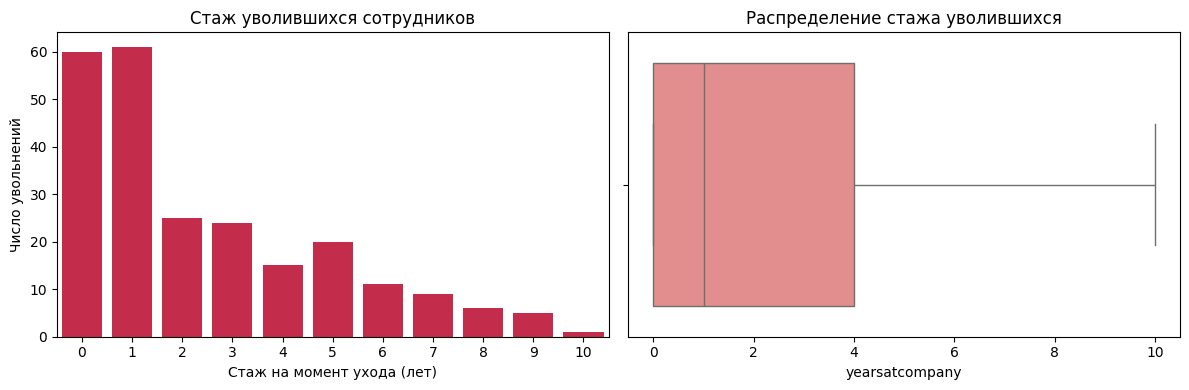

In [ ]:
# Фильтруем датафрейм, оставляя только уволившихся
df_exited = df[df['attrition_flag'] == 1]
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
years_counts_exited = df_exited['yearsatcompany'].value_counts().sort_index()
sns.barplot(x=years_counts_exited.index, y=years_counts_exited.values, color='crimson')
plt.title('Стаж уволившихся сотрудников')
plt.xlabel('Стаж на момент ухода (лет)')
plt.ylabel('Число увольнений')

plt.subplot(1, 2, 2)
sns.boxplot(x=df_exited['yearsatcompany'], color='lightcoral')
plt.title('Распределение стажа уволившихся')

plt.tight_layout()
plt.show()

На графике видим пик увольнения на 0 и 1 году работы в компании.
На втором графике мы видим, что медиана проходит на стаже 1 год. 50% всех уволившихся сотрудников покинули компанию проработав менее 2х лет, а вторые 50% уволились, имея стаж 2 года и более

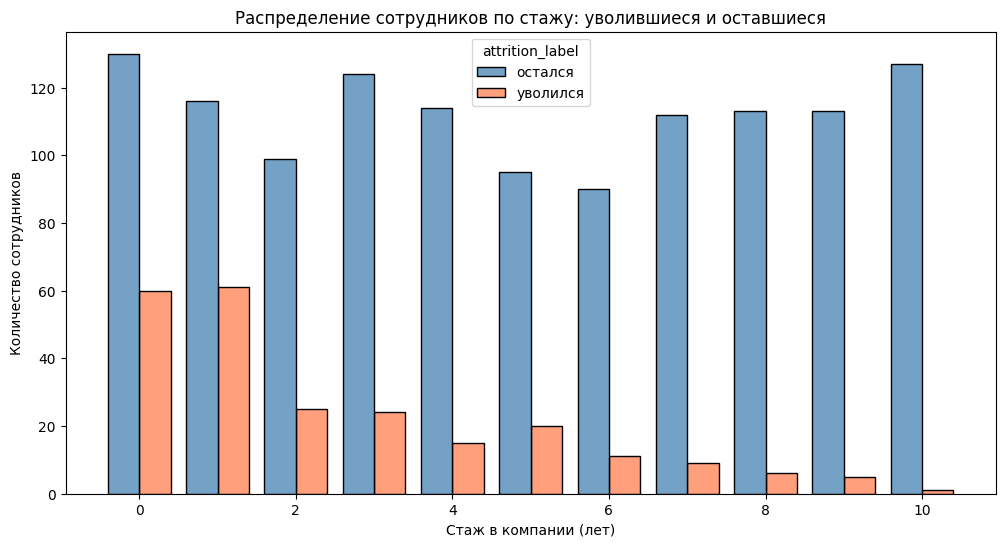

In [ ]:
# Построим сравнительную гистограмму
df['attrition_label'] = df['attrition_flag'].map({0: 'остался', 1: 'уволился'})

plt.figure(figsize=(12, 6))
sns.histplot(
    data=df,
    x='yearsatcompany',
    hue='attrition_label',
    hue_order=['остался', 'уволился'],
    palette={'остался': 'steelblue', 'уволился': 'coral'},
    multiple='dodge',
    discrete=True,
    shrink=0.8
)
plt.title('Распределение сотрудников по стажу: уволившиеся и оставшиеся')
plt.xlabel('Стаж в компании (лет)')
plt.ylabel('Количество сотрудников')
plt.show()

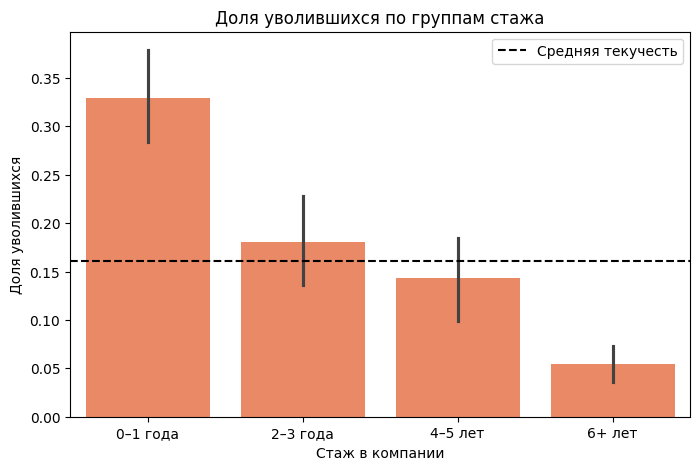

In [ ]:
# Посмотрим долю текучести по группам стажа
df['years_bin4'] = pd.cut(
    df['yearsatcompany'],
    bins=[0, 2, 4, 6, np.inf],
    labels=['0–1 года', '2–3 года', '4–5 лет', '6+ лет'],
    right=False
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=df,
    x='years_bin4',
    y='attrition_flag',
    order=['0–1 года', '2–3 года', '4–5 лет', '6+ лет'],
    errorbar=('ci', 95),
    color='coral'
)
plt.axhline(df['attrition_flag'].mean(), color='black', linestyle='--',
            label='Средняя текучесть')
plt.title('Доля уволившихся по группам стажа')
plt.ylabel('Доля уволившихся')
plt.xlabel('Стаж в компании')
plt.legend()
plt.show()

In [ ]:
# Сводная таблица по группам стажа
pivot = df.pivot_table(
    index='years_bin4',
    values='attrition_flag',
    aggfunc=['mean', 'sum', 'count']
)

pivot.columns = ['Текучесть (%)', 'Уволилось (чел)', 'Всего в группе']
pivot['Текучесть (%)'] = pivot['Текучесть (%)'] * 100

print("\nОбщая статистика по группам:")
print(pivot)


Общая статистика по группам:
            Текучесть (%)  Уволилось (чел)  Всего в группе
years_bin4                                                
0–1 года        32.970027              121             367
2–3 года        18.014706               49             272
4–5 лет         14.344262               35             244
6+ лет           5.451448               32             587


/tmp/ipykernel_972/74669350.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = df.pivot_table(
/tmp/ipykernel_972/74669350.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = df.pivot_table(
/tmp/ipykernel_972/74669350.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = df.pivot_table(


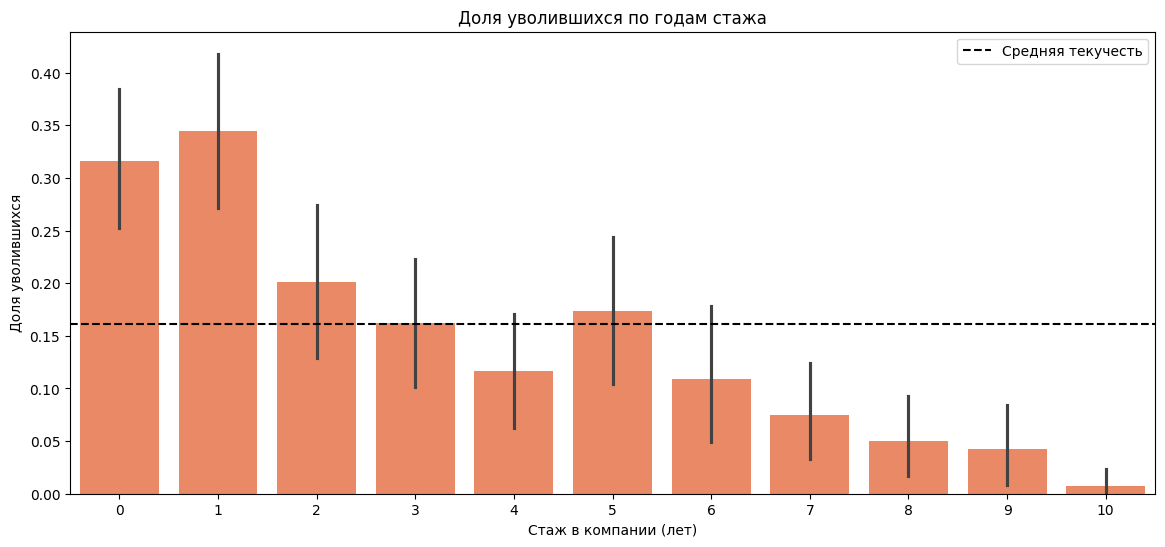

In [ ]:
# Посмотрим долю текучести по годам стажа
plt.figure(figsize=(14, 6))

sns.barplot(
    data=df,
    x='yearsatcompany',
    y='attrition_flag',
    errorbar=('ci', 95),
    color='coral'
)

plt.axhline(df['attrition_flag'].mean(), color='black', linestyle='--',
            label='Средняя текучесть')
plt.title('Доля уволившихся по годам стажа')
plt.xlabel('Стаж в компании (лет)')
plt.ylabel('Доля уволившихся')
plt.legend()
plt.show()

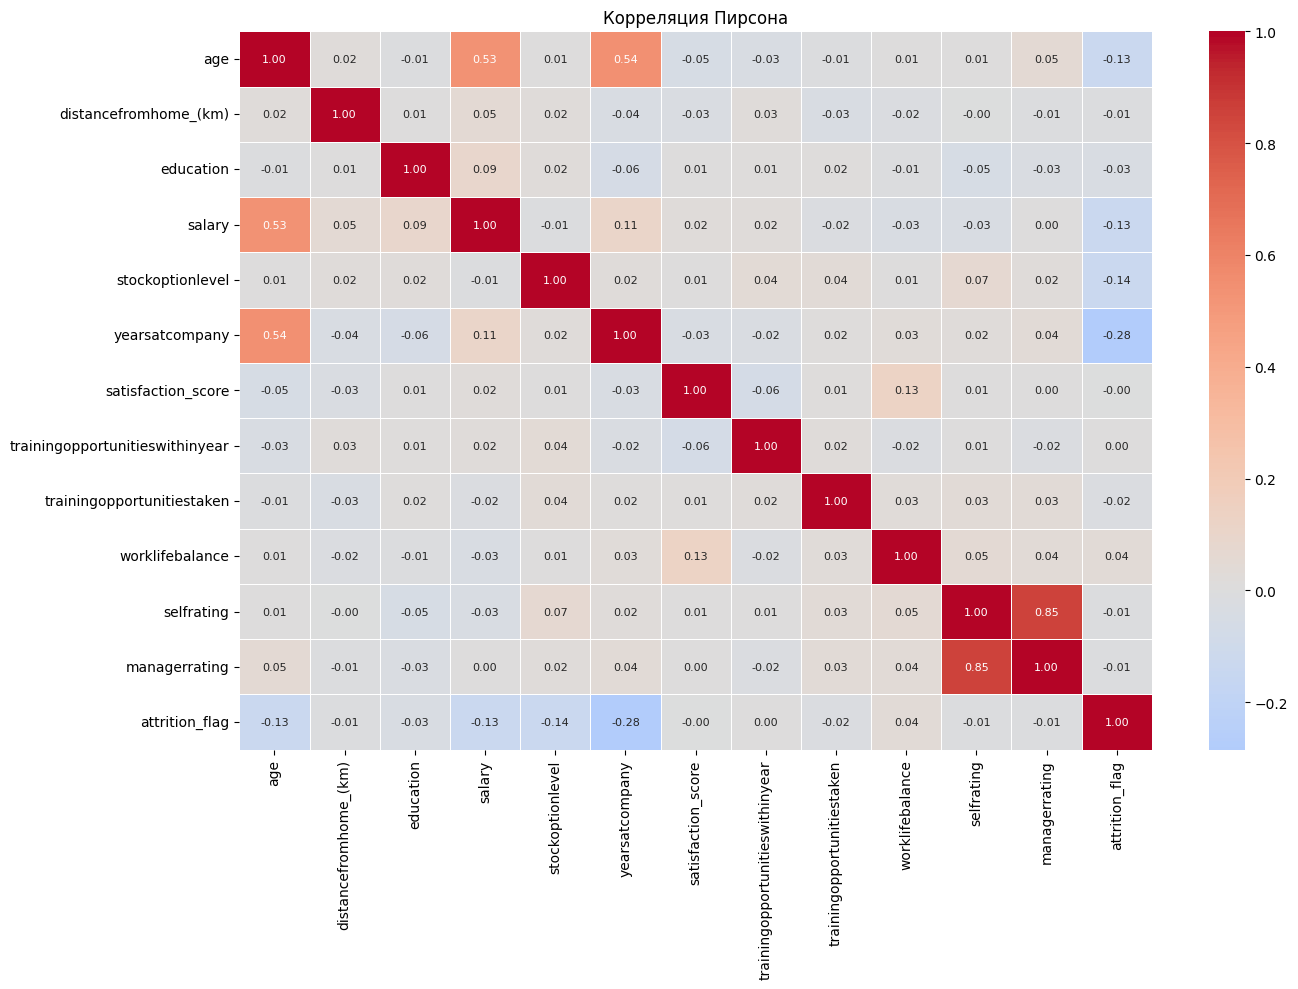

In [ ]:
# Выведем в корреляционную матрицу Пирсона только содержательные признаки, убираем технические дубли и факторы создающие мультиколлинеарность
satisfaction_cols = [
    'age', 'distancefromhome_(km)', 'education', 'salary', 'stockoptionlevel',
    'yearsatcompany', 'satisfaction_score',
    'trainingopportunitieswithinyear', 'trainingopportunitiestaken',
    'worklifebalance', 'selfrating', 'managerrating',
    'attrition_flag'
]

corr = df[satisfaction_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, annot_kws={'size': 8})
plt.title('Корреляция Пирсона')
plt.tight_layout()
plt.show()

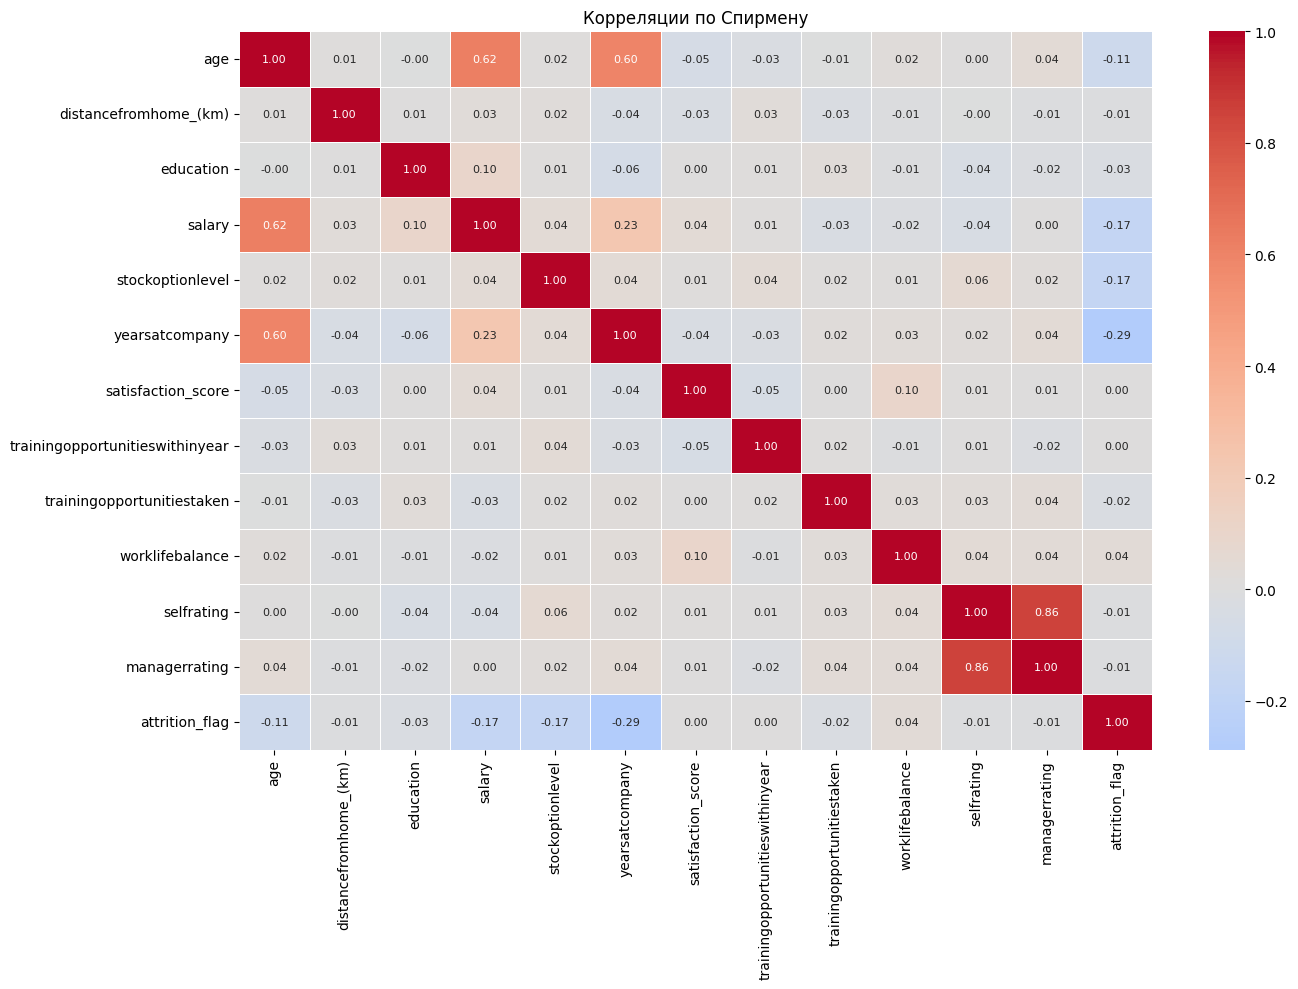

In [ ]:
# Корреляция Спирмена
satisfaction_cols = [
    'age', 'distancefromhome_(km)', 'education', 'salary', 'stockoptionlevel',
    'yearsatcompany', 'satisfaction_score',
    'trainingopportunitieswithinyear', 'trainingopportunitiestaken',
    'worklifebalance', 'selfrating', 'managerrating',
    'attrition_flag'
]

# Корреляция Спирмена (method='spearman')
corr_spearman = df[satisfaction_cols].corr(method='spearman')

plt.figure(figsize=(14, 10))
sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, annot_kws={'size': 8})
plt.title('Корреляции по Спирмену')
plt.tight_layout()
plt.show()


In [ ]:
# Таблица сопряжённости
ct = pd.crosstab(df['years_bin4'], df['attrition_flag'])
print(ct)

chi2, p, dof, expected = chi2_contingency(ct)

n = ct.values.sum()
cramer_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))  # сила связи

print(f"\nХи-квадрат = {chi2:.2f}, df = {dof}, p-value = {p:.4f}")
print(f"Крамер V = {cramer_v:.3f}")

attrition_flag    0    1
years_bin4              
0–1 года        246  121
2–3 года        223   49
4–5 лет         209   35
6+ лет          555   32

Хи-квадрат = 127.75, df = 3, p-value = 0.0000
Крамер V = 0.295


P-value = 0.0000 Нулевая гипотеза ($H_0$) отвергается. Связь между сроком работы и увольнением статистически значима. Это не случайность. V = 0.295 умеренная связь.

В исходных данных выявлены записи с нарушением логики временных меток (дата приема позже даты опроса или дата опроса превышает дату приема плюс стаж). Чтобы проверить, не являются ли эти аномалии "шумом", искажающим статистическую связь между стажем и увольнением, мы выполним анализ чувствительности: сравним результаты теста Хи-квадрат на полной выборке и на подвыборке, очищенной от аномалий.

In [ ]:
# Cравним риски увольнения между двумя группами сотрудников
attrition_anom = df[df['review_date_anomaly'] == 1]['attrition_flag'].mean() * 100
attrition_norm = df[df['review_date_anomaly'] == 0]['attrition_flag'].mean() * 100

print(f"Доля уволившихся (Аномалии): {attrition_anom:.1f}%")
print(f"Доля уволившихся (Норма): {attrition_norm:.1f}%")

# Статистическая проверка разницы долей
count = [df[df['review_date_anomaly'] == 1]['attrition_flag'].sum(),
         df[df['review_date_anomaly'] == 0]['attrition_flag'].sum()]
nobs = [len(df[df['review_date_anomaly'] == 1]),
        len(df[df['review_date_anomaly'] == 0])]

z_stat, p_val_prop = proportions_ztest(count, nobs)
print(f"P-value разницы в текучести: {p_val_prop:.4f}")

Доля уволившихся (Аномалии): 31.9%
Доля уволившихся (Норма): 13.8%
P-value разницы в текучести: 0.0000


Сотрудники, у которых в данных есть аномалии (ошибки в датах), увольняются в 2.3 раза чаще, чем сотрудники с корректными данными.  
Если мы удалим аномалии, мы удалим самых рискованных сотрудников и сделаем неверный вывод, что "в компании всё спокойно".   
Если мы оставим аномалии, мы сможем использовать их как "красный флаг" для поиска людей, которые скоро уйдут.

In [ ]:
# Таблица сопряжённости для строк без аномалий
df_clean = df[df['review_date_anomaly'] == 0].copy()

print(f"Исходный размер данных: {len(df)}")
print(f"Размер данных БЕЗ аномалий: {len(df_clean)}")

ct_clean = pd.crosstab(df_clean['years_bin4'], df_clean['attrition_flag'])

print("\nТаблица сопряженности (без аномалий):")
print(ct_clean)

chi2, p, dof, expected = chi2_contingency(ct_clean)

n = ct_clean.values.sum()

# Защита от ошибки, если в выборке осталась только 1 группа стажа
if min(ct_clean.shape) > 1:
    cramer_v = np.sqrt(chi2 / (n * (min(ct_clean.shape) - 1)))
else:
    cramer_v = np.nan

print(f"\nХи-квадрат = {chi2:.2f}, df = {dof}, p-value = {p:.4f}")
print(f"Крамер V = {cramer_v:.3f}")

Исходный размер данных: 1470
Размер данных БЕЗ аномалий: 1279

Таблица сопряженности (без аномалий):
attrition_flag    0   1
years_bin4             
0–1 года        201  60
2–3 года        150  49
4–5 лет         197  35
6+ лет          555  32

Хи-квадрат = 73.01, df = 3, p-value = 0.0000
Крамер V = 0.239


Исключение 191 записи с несогласованными датами (13% выборки) не повлияло на вывод — связь стажа и увольнения сохраняется (χ² = 73.0, p < 0.001, V Крамера = 0.239). Сила эффекта на очищенных данных умеренная, что лишь незначительно ниже оценки по полному массиву (0.295).

Стратегический вывод: Несмотря на корректировку силы связи, зависимость остается статистически значимой ($p < 0.001$). Пик риска увольнений приходится на сотрудников со стажем до 2 лет.

## Профиль данных и ограничения исследования

1. Единица наблюдения и гранулярность

Единица наблюдения: employeeid (код уникален)  
Гранулярность: Таблица Employee.csv: 1 строка = 1 сотрудник (статический профиль).  
Таблица PerformanceRating.csv (или Survey): 1 строка = 1 оценка/опрос (может быть несколько строк на сотрудника).  
Итоговый df: 1 строка = 1 сотрудник, последний оценка/опрос

2. Ключи, уникальность и связи

Первичный ключ: employeeid.  
Уникальность: В Employee.csv — строго 1 запись на ID.  
В PerformanceRating.csv — дубликаты по employee_id возможны (один человек — несколько опросов).  
Типы связей (в итоговом датасете):
Employee $\rightarrow$ Last_PerformanceRating: One-to-One (Один к одному).   
Обоснование: Каждая строка сотрудника (employeeid) однозначно соответствует значениям его последнего опроса.  
Дубликаты employee_id в итоговом наборе отсутствуют.

3. Смысл полей, пропусков и специальных значений

attrition_flag (Целевая переменная): 1 — уволился, 0 — активен.  
yearsatcompany (Стаж): в диапазоне 0 — 10  
review_date_anomaly (Флаг аномалии): 1 — дата опроса логически невозможна (раньше найма или позже, чем позволяет стаж).  
Пропуски (NULL):
В satisfaction_score и датах опросов пропуски означают "опрос не был назначен/не пройден".

4. Временное и объектное покрытие

Временное покрытие: Данные охватывают hiredate  с 2012-01-03 по 2022-12-31.  
Объектное покрытие: Выборка включает 1470 уникальных сотрудников.

##План проверки

Для понимания профиля сотрудников, покидающих компанию, были проанализированы распределения стажа на момент ухода, анализ матрицы Пирсона по ключевым признакам.   

Сотрудники были сгруппированы по стажу (years_bin4: 0–1, 2–3, 4–5, 6+ лет), чтобы оценить риск на каждом этапе.   

Для статистической проверки сформулирована нулевая и альтернативная гипотезы:  
Нулевая гипотеза ($H_0$): Срок работы в компании не связан с вероятностью увольнения. Распределение стажа среди уволившихся сотрудников не отличается от распределения стажа среди работающих.  
Альтернативная гипотеза ($H_1$): Вероятность увольнения зависит от срока работы, демонстрируя статистически значимый пик на первом году (интервал 0–1 года).  

Для проверки гипотезы использовалась комбинация визуального анализа и статистических тестов:  
Хи-квадрат = 127.75   
P-value = 0.0000  
V Крамера = 0.295.  
Интерпретация: P-value $< 0.05$ позволяет отвергнуть $H_0$. Связь статистически значима.    
V Крамера (0.295) говорит об умеренной силе связи: стаж важен, но не является единственным фактором риска.

Проверили, как логические ошибки в датах (review_date_anomaly) влияют на выводы: Сотрудники с ошибками в датах увольняются в 2.3 раза чаще.   
На всех данных: V Крамера = 0.295.  
Только чистые данные: V Крамера = 0.239    
Удаление аномалий ослабляет статистический сигнал, так как мы фактически удаляем самых рискованных сотрудников.


## Вывод:
Нулевая гипотеза (H₀) о том, что срок работы в компании не связан с вероятностью увольнения, **отвергается**  
Связь между стажем и текучестью — это не случайность, а объективная закономерность.  
Вероятность увольнения зависит от срока работы, демонстрируя пики на сроке до 2х лет.   
Хи-квадрат по группам стажа: χ² = 127.75 (df = 3), p < 0.001 — доли уволившихся статистически значимо различаются между группами стажа.  
Сила связи по Крамеру V = 0.295 — это умеренная связь.  
Стаж — значимый фактор, но он не предсказывает увольнение на 100%, накладываются и другие факторы.  
Рекомендуется внедрить регламент онбординга именно для этого периода.